In [2]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("vishesh1412/celebrity-face-image-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'celebrity-face-image-dataset' dataset.
Path to dataset files: /kaggle/input/celebrity-face-image-dataset


In [3]:
import os

# List the contents of the downloaded directory
print(os.listdir(path))

['Celebrity Faces Dataset']


In [4]:
import os
import cv2
import numpy as np
from sklearn.model_selection import train_test_split

# Assuming the dataset is downloaded to the path variable
image_dir = os.path.join(path, 'Celebrity Faces Dataset')

images = []
labels = []
celebrity_names = []

# Load images and labels
for i, celebrity_name in enumerate(os.listdir(image_dir)):
    celebrity_names.append(celebrity_name)
    celebrity_dir = os.path.join(image_dir, celebrity_name)
    for image_file in os.listdir(celebrity_dir):
        image_path = os.path.join(celebrity_dir, image_file)
        image = cv2.imread(image_path)
        image = cv2.resize(image, (128, 128)) # Resize images
        images.append(image)
        labels.append(i)

images = np.array(images)
labels = np.array(labels)

# Since the user wants to train on the entire dataset, we won't split into train/test

# Normalize pixel values
images = images.astype('float32') / 255.0

# Display shapes of the loaded data
print("Shape of images:", images.shape)
print("Shape of labels:", labels.shape)
print("Number of celebrities:", len(celebrity_names))

Shape of images: (1800, 128, 128, 3)
Shape of labels: (1800,)
Number of celebrities: 17


In [5]:
import tensorflow as tf
from tensorflow.keras import layers, models

# Define a simple CNN model
def create_cnn_model(input_shape, num_classes):
    model = models.Sequential()
    model.add(layers.Conv2D(32, (3, 3), activation='relu', input_shape=input_shape))
    model.add(layers.MaxPooling2D((2, 2)))
    model.add(layers.Conv2D(64, (3, 3), activation='relu'))
    model.add(layers.MaxPooling2D((2, 2)))
    model.add(layers.Conv2D(128, (3, 3), activation='relu'))
    model.add(layers.MaxPooling2D((2, 2)))
    model.add(layers.Flatten())
    model.add(layers.Dense(128, activation='relu'))
    model.add(layers.Dense(num_classes, activation='softmax'))
    return model

# Get input shape and number of classes from the loaded data
input_shape = images[0].shape
num_classes = len(celebrity_names)

# Create the model
model = create_cnn_model(input_shape, num_classes)

# Display the model summary
model.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 17)             │         2,193 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,306,833 (12.61 MB)

 Trainable params: 3,306,833 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_3 (Sequential)       │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ ?                      │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,257,984 (8.61 MB)

 Trainable params: 1,526,400 (5.82 MB)

 Non-trainable params: 731,584 (2.79 MB)

Epoch 1/35
45/45 ━━━━━━━━━━━━━━━━━━━━ 16s 153ms/step - accuracy: 0.0800 - loss: 2.9293 - val_accuracy: 0.0500 - val_loss: 2.9362 - learning_rate: 1.0000e-05
Epoch 2/35
45/45 ━━━━━━━━━━━━━━━━━━━━ 4s 92ms/step - accuracy: 0.1004 - loss: 2.8716 - val_accuracy: 0.0500 - val_loss: 2.9309 - learning_rate: 1.0000e-05
Epoch 3/35
45/45 ━━━━━━━━━━━━━━━━━━━━ 4s 96ms/step - accuracy: 0.1034 - loss: 2.8379 - val_accuracy: 0.0500 - val_loss: 2.9282 - learning_rate: 1.0000e-05
Epoch 4/35
45/45 ━━━━━━━━━━━━━━━━━━━━ 4s 93ms/step - accuracy: 0.0953 - loss: 2.8291 - val_accuracy: 0.0583 - val_loss: 2.9241 - learning_rate: 1.0000e-05
Epoch 5/35
45/45 ━━━━━━━━━━━━━━━━━━━━ 4s 93ms/step - accuracy: 0.1009 - loss: 2.8175 - val_accuracy: 0.0639 - val_loss: 2.9140 - learning_rate: 1.0000e-05
Epoch 6/35
45/45 ━━━━━━━━━━━━━━━━━━━━ 5s 106ms/step - accuracy: 0.1237 - loss: 2.7992 - val_accuracy: 0.0639 - val_loss: 2.9077 - learning_rate: 1.0000e-05
Epoch 7/35
45/45 ━━━━━━━━━━━━━━━━━━━━ 6s 133ms/step - accuracy: 0.1

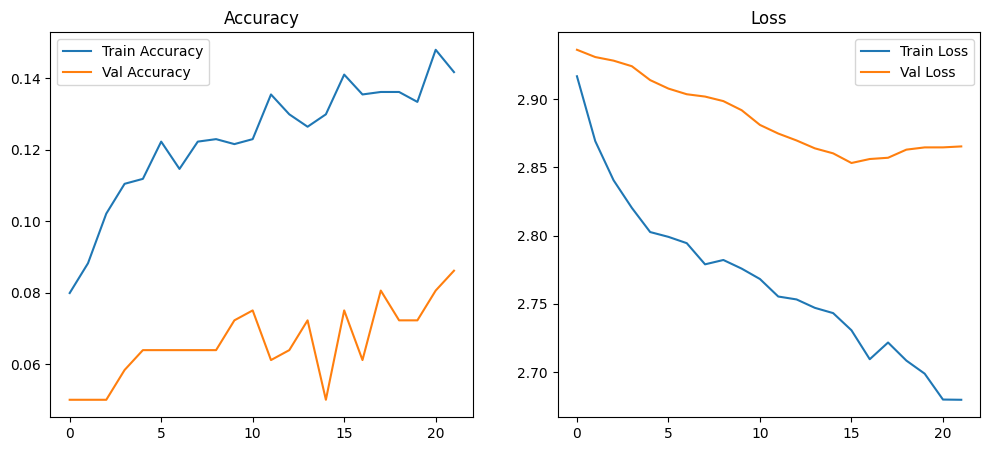

In [7]:
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import numpy as np # Import numpy

# -------------------------------
# 1) Resize and Preprocess Images
# -------------------------------
# MobileNetV2 requires 224x224 input
images_resized = tf.image.resize(images, (224, 224))

# Use correct MobileNetV2 preprocessing (IMPORTANT)
images_preprocessed = tf.keras.applications.mobilenet_v2.preprocess_input(images_resized)

# Convert tensors to numpy arrays for train_test_split compatibility
images_np = images_preprocessed.numpy()
labels_np = labels # Assuming labels is already a numpy array


# -------------------------------
# 2) Train / Validation Split
# -------------------------------
X_train, X_val, y_train, y_val = train_test_split(
    images_np, labels_np, test_size=0.2, random_state=42, shuffle=True
)

# -------------------------------
# 3) Data Augmentation
# -------------------------------
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.15),
    layers.RandomZoom(0.15),
])

# -------------------------------
# 4) Load MobileNetV2 (Transfer Learning)
# -------------------------------
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

# Freeze most layers, fine-tune last 30 layers
fine_tune_at = len(base_model.layers) - 30
for layer in base_model.layers[:fine_tune_at]:
    layer.trainable = False
for layer in base_model.layers[fine_tune_at:]:
    layer.trainable = True

# -------------------------------
# 5) Build Final Model (Added Layers)
# -------------------------------
model = models.Sequential([
    data_augmentation,
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dense(512, activation='relu'),   # Added layer
    layers.Dropout(0.4),
    layers.Dense(256, activation='relu'),   # Added layer
    layers.Dropout(0.3),
    layers.Dense(len(celebrity_names), activation='softmax')
])

# -------------------------------
# 6) Compile Model
# -------------------------------
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),   # Low LR important for fine-tuning
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

# -------------------------------
# 7) Training Callbacks
# -------------------------------
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=6,
    restore_best_weights=True
)

lr_schedule = tf.keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss',
    patience=3,
    factor=0.3,
    min_lr=1e-7,
    verbose=1
)

# -------------------------------
# 8) Train Model
# -------------------------------
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=35,                # More epochs since fine-tuning is stable
    batch_size=32,
    callbacks=[early_stop, lr_schedule]
)

# -------------------------------
# 9) Evaluate Model
# -------------------------------
loss, accuracy = model.evaluate(X_val, y_val)
print(f"\n✅ Final Validation Accuracy: {accuracy*100:.2f}%")

# -------------------------------
# 10) Plot Curves
# -------------------------------
plt.figure(figsize=(12,5))

# Accuracy Plot
plt.subplot(1,2,1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Val Accuracy')
plt.title("Accuracy")
plt.legend()

# Loss Plot
plt.subplot(1,2,2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.title("Loss")
plt.legend()

plt.show()

Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_5 (Sequential)       │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_128            │ (None, 4, 4, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ ?                      │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,257,984 (8.61 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 2,257,984 (8.61 MB)

Epoch 1/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 9s 86ms/step - accuracy: 0.0680 - loss: 3.0767 - val_accuracy: 0.1139 - val_loss: 2.8201 - learning_rate: 0.0010
Epoch 2/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step - accuracy: 0.0781 - loss: 2.8383 - val_accuracy: 0.1139 - val_loss: 2.8330 - learning_rate: 0.0010
Epoch 3/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 28ms/step - accuracy: 0.1103 - loss: 2.8240 - val_accuracy: 0.1139 - val_loss: 2.8304 - learning_rate: 0.0010
Epoch 4/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.1257 - loss: 2.8281
Epoch 4: ReduceLROnPlateau reducing learning rate to 0.00020000000949949026.
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 28ms/step - accuracy: 0.1253 - loss: 2.8282 - val_accuracy: 0.1139 - val_loss: 2.8290 - learning_rate: 0.0010
Epoch 5/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step - accuracy: 0.1198 - loss: 2.8271 - val_accuracy: 0.1139 - val_loss: 2.8287 - learning_rate: 2.0000e-04
Epoch 6/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 28ms/step - accuracy: 0.1036 - loss: 2.8281 - val

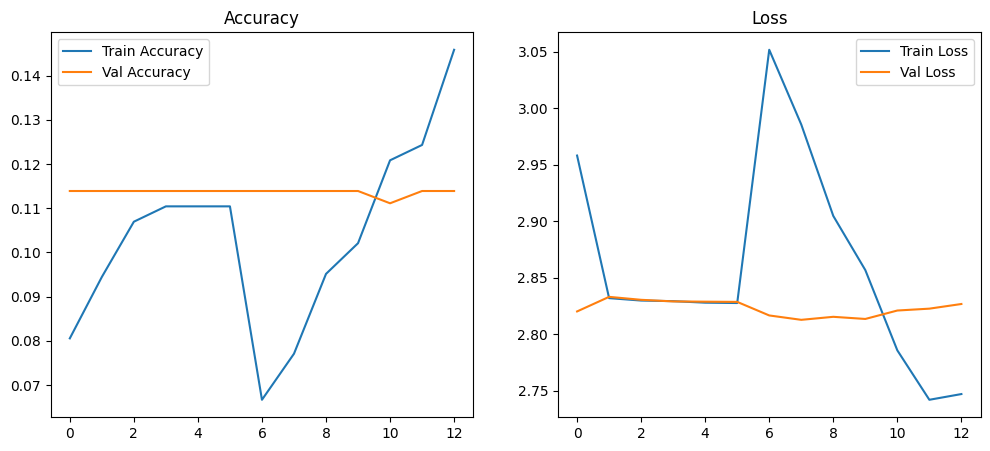

In [8]:
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

# -----------------------------
# 1) Convert Images to Tensors
# -----------------------------
images = images / 255.0   # Normalize pixel values

# Split dataset (80% train, 20% validation)
X_train, X_val, y_train, y_val = train_test_split(images, labels, test_size=0.2, shuffle=True)

# -----------------------------
# 2) Data Augmentation (Important)
# -----------------------------
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
])

# -----------------------------
# 3) Transfer Learning: MobileNetV2
# -----------------------------
base_model = tf.keras.applications.MobileNetV2(
    input_shape=X_train[0].shape,
    include_top=False,
    weights="imagenet"
)
base_model.trainable = False  # Freeze layers initially

model = models.Sequential([
    data_augmentation,
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dense(256, activation='relu'),
    layers.Dropout(0.4),
    layers.Dense(len(celebrity_names), activation='softmax')
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

# -----------------------------
# 4) Callbacks for Best Results
# -----------------------------
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

lr_schedule = tf.keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss',
    patience=3,
    factor=0.2,
    verbose=1
)

# -----------------------------
# 5) Train Model (Phase 1)
# -----------------------------
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=20,
    batch_size=32,
    callbacks=[early_stop, lr_schedule]
)

# -----------------------------
# 6) Fine-Tune (Unfreeze Some Layers)
# -----------------------------
base_model.trainable = True
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.00001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

history_ft = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=10,
    batch_size=32,
    callbacks=[early_stop, lr_schedule]
)

# -----------------------------
# 7) Evaluate Final Model
# -----------------------------
loss, accuracy = model.evaluate(X_val, y_val)
print(f"\n✅ Final Validation Accuracy: {accuracy*100:.2f}%")

# -----------------------------
# 8) Plot Accuracy & Loss
# -----------------------------
plt.figure(figsize=(12,5))

# Training/Validation Accuracy
plt.subplot(1,2,1)
plt.plot(history.history['accuracy'] + history_ft.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'] + history_ft.history['val_accuracy'], label='Val Accuracy')
plt.title("Accuracy")
plt.legend()

# Training/Validation Loss
plt.subplot(1,2,2)
plt.plot(history.history['loss'] + history_ft.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'] + history_ft.history['val_loss'], label='Val Loss')
plt.title("Loss")
plt.legend()

plt.show()
